# BANKING77: output control and reasoning

Two questions on top of the scaling experiment (`01_banking77_qwen_scaling.ipynb`):

1. **Structured vs. open answers.** How much does it matter that we *force* the model to emit a valid label?
2. **Reasoning.** Does letting a small model think before answering improve accuracy, and what does it cost?

Results are cached under `results/banking77/<mode>_<think|no-think>/`; the same runs are available as
`scripts/run_banking77.py --mode ... [--think]`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import LLMClassifier, evaluate, score, stratified_subset
from slm.evaluation.classification import ANSWER_FORMATS, INVALID
from slm.inference import THINKING_OPTIONS, OllamaBackend, params_in_billions

pd.set_option("display.max_colwidth", 200)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order
RESULTS = RESULTS_DIR / "banking77"
dataset = load_banking77()


def run(model, mode="structured", think=False, data=None, workers=4):
    """Evaluate one configuration (cached) and return per-example results."""
    backend = OllamaBackend(model, think=think, **(THINKING_OPTIONS if think else {}))
    cache = RESULTS / f"{mode}_{'think' if think else 'no-think'}" / f"{model.replace(':', '_')}.jsonl"
    return evaluate(LLMClassifier(backend, dataset.labels, mode=mode), data, cache_file=cache, workers=workers)


def style(ax, title):
    ax.set_title(title, loc="left")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1: Structured vs. open answers

Two levels of output control, with the same prompt except for the last line:

| mode | what Ollama enforces | answer instruction |
|---|---|---|
| `structured` | JSON schema with an `enum` of the 77 labels (constrained decoding) | JSON object |
| `free` | nothing | intent name only |

Free answers are scored twice: **strict** (the answer must be exactly a label) and **lenient**
(case, quotes, spaces vs. underscores, small typos and labels embedded in a sentence are forgiven).

In [2]:
MODES = ["structured", "free"]
for mode in MODES:
    print(f"{mode:>10}: {ANSWER_FORMATS[mode]}")

structured: Answer with a JSON object of the form {"label": "<intent>"}.
      free: Answer with the name of the intent only, exactly as written in the list above.


In [3]:
MODELS = ["qwen3.5:0.8b", "qwen3.5:2b", "qwen3.5:4b", "qwen3.5:9b"]
PART1_MODELS = MODELS + ["qwen3.6:35b-a3b"]  # plus the large mixture-of-experts model (3B active parameters)
subset = stratified_subset(dataset.test, per_class=10)  # 770 queries

outputs, rows = {}, []
for mode in MODES:
    for model in PART1_MODELS:
        outputs[mode, model] = res = run(model, mode, data=subset)
        rows.append({"mode": mode, "model": model, "params_b": params_in_billions(model), **score(res)})
modes = pd.DataFrame(rows)
modes.pivot(index="model", columns="mode", values=["accuracy", "accuracy_lenient", "invalid_rate"]).round(3)

qwen3.5:0.8b: 0it [00:00, ?it/s]

qwen3.5:0.8b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

...

qwen3.5:9b: 0it [00:00, ?it/s]

qwen3.5:9b: 0it [00:00, ?it/s]

qwen3.6:35b-a3b: 0it [00:00, ?it/s]

qwen3.6:35b-a3b: 0it [00:00, ?it/s]

accuracy            accuracy_lenient            invalid_rate  \
mode                free structured             free structured         free   
model                                                                          
qwen3.5:0.8b       0.456      0.449            0.462      0.449        0.026   
qwen3.5:2b         0.516      0.500            0.521      0.500        0.016   
qwen3.5:4b         0.651      0.656            0.653      0.656        0.005   
qwen3.5:9b         0.694      0.696            0.696      0.696        0.004   
qwen3.6:35b-a3b    0.744      0.752            0.744      0.752        0.003   

                            
mode            structured  
model                       
qwen3.5:0.8b           0.0  
qwen3.5:2b             0.0  
qwen3.5:4b             0.0  
qwen3.5:9b             0.0  
qwen3.6:35b-a3b        0.0

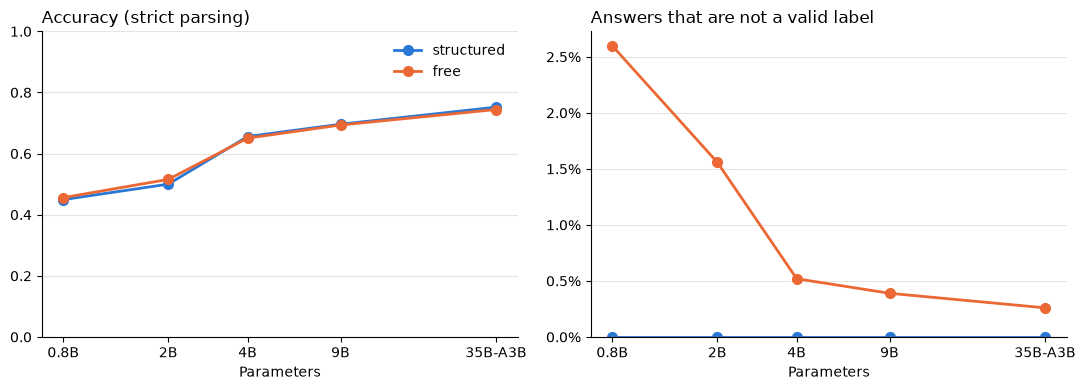

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for color, mode in zip(COLORS, MODES):
    grp = modes[modes["mode"] == mode].sort_values("params_b")
    axes[0].plot(grp["params_b"], grp["accuracy"], marker="o", markersize=7, linewidth=2, color=color, label=mode)
    axes[1].plot(grp["params_b"], grp["invalid_rate"], marker="o", markersize=7, linewidth=2, color=color, label=mode)
for ax, title in zip(axes, ["Accuracy (strict parsing)", "Answers that are not a valid label"]):
    ax.set_xscale("log")
    ax.set_xticks(modes["params_b"].unique(), [m.split(":")[1].upper() for m in modes["model"].unique()])
    ax.minorticks_off()
    ax.set_xlabel("Parameters")
    style(ax, title)
axes[0].set_ylim(0, 1)
axes[1].set_ylim(bottom=0)
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
axes[0].legend(frameon=False)
fig.tight_layout()

### What do invalid answers look like?

Typical failure modes of unconstrained output: invented labels, paraphrases, extra words.
Lenient parsing recovers some of them, at the price of hand-written matching rules.

In [5]:
res = pd.concat({model: outputs["free", model] for model in PART1_MODELS}, names=["model"])
invalid = res[res["prediction"] == INVALID]
invalid[["text", "label", "raw", "prediction_lenient"]].groupby(level="model").head(4)

text  \
model                                                                                       
qwen3.5:0.8b    370                               How can I get my physical card to work?   
                498   Do you offer services for children to have money saving experience?   
                1363                How do I make more than one disposable card in a day?   
                1364                            Can I have more than one disposable card?   
qwen3.5:2b      41                                    I would like to reactivate my card.   
                673                                 Where is the money I topped off with?   
                1335                         How do I transfer money using a credit card?   
                1343                            Help me transfer money to my credit card.   
qwen3.5:4b      1636                                What does a pending transaction mean?   
                2095                        Do you know why my card payment was reverted?   
                2505                            What are the fees to get a physical card?   
                2623           What is the process of obtaining a disposable virtual card   
qwen3.5:9b      1265                                      Where is my PIN number located?   
                1335                         How do I transfer money using a credit card?   
                1340              Is there a way to transfer funds directly from my card?   
qwen3.6:35b-a3b 2321                      I'm out of money, can I add money with my bank?   
                2477                                            How can I top-up my card?   

                                            label  \
model                                               
qwen3.5:0.8b    370              card_not_working   
                498                     age_limit   
                1363       disposable_card_limits   
                1364       disposable_card_limits   
qwen3.5:2b      41                   card_linking   
                673                pending_top_up   
                1335           topping_up_by_card   
                1343           topping_up_by_card   
qwen3.5:4b      1636         pending_card_payment   
                2095       reverted_card_payment?   
                2505          order_physical_card   
                2623  get_disposable_virtual_card   
qwen3.5:9b      1265            get_physical_card   
                1335           topping_up_by_card   
                1340           topping_up_by_card   
qwen3.6:35b-a3b 2321        transfer_into_account   
                2477     top_up_by_cash_or_cheque   

                                                  raw  \
model                                                   
qwen3.5:0.8b    370             getting_physical_card   
                498                                no   
                1363  getting_disposable_virtual_card   
                1364                              yes   
qwen3.5:2b      41            reactivate_card_payment   
                673                    top_up_by_card   
                1335                   top_up_by_card   
                1343                   top_up_by_card   
qwen3.5:4b      1636              pending_transaction   
                2095            reverted_card_payment   
                2505            getting_physical_card   
                2623  getting_disposable_virtual_card   
qwen3.5:9b      1265                     where_is_pin   
                1335                   top_up_by_card   
                1340                   top_up_by_card   
qwen3.6:35b-a3b 2321          top_up_by_bank_transfer   
                2477                   top_up_by_card   

                                  prediction_lenient  
model                                                 
qwen3.5:0.8b    370                get_physical_card  
                498                        <invalid>  
     

In [6]:
# Invented labels: answers that are not a label even after lenient matching
invented = invalid[invalid["prediction_lenient"] == INVALID]
invented.groupby(level="model")["raw"].agg(lambda s: s.str.strip().value_counts().head(5).to_dict())

model
qwen3.5:0.8b    {'yes': 2, 'no': 1, 'get_top_up_verification_code': 1}
qwen3.5:2b                                  {'salary_not_received': 1}
qwen3.5:4b                                  {'pending_transaction': 1}
qwen3.5:9b                                         {'where_is_pin': 1}
Name: raw, dtype: object

## Part 1b: Does a short explanation help?

The structured answer is a single label. What if the model may explain its decision in the same JSON object?
The **order of the keys** matters, because the model writes token by token (the schema fixes the order):

* `{"label": ..., "reason": ...}`: the label is written first, so the reason cannot change it; it is a
  justification after the fact.
* `{"reason": ..., "label": ...}`: the model first writes one or two sentences, then picks the label from the
  enum: a small chain of thought inside the JSON.

The label is still restricted to the 77 intents, and the reason to 300 characters. Same balanced subset as in
Part 2 (5 queries per intent, 385 queries); run with `scripts/run_banking77.py --per-class 5 --explanation before`
(or `after`).

In [7]:
subset = stratified_subset(dataset.test, per_class=5)  # 385 queries
VARIANTS = {"label only": "structured_no-think", "reason after label": "structured-reason-after_no-think",
            "reason before label": "structured-reason-before_no-think"}


def load_run(run, model):
    path = RESULTS / run / f"{model.replace(':', '_')}.jsonl"
    records = pd.read_json(path, lines=True).set_index("idx")
    results = subset.join(records, how="inner")
    results["correct"] = results["prediction"] == results["label"]
    return results


explained = {(variant, model): load_run(run, model) for variant, run in VARIANTS.items() for model in MODELS}
explain_summary = pd.DataFrame([{"variant": variant, "model": model, "accuracy": r["correct"].mean(),
                                 "tokens": r["completion_tokens"].mean(), "latency_s": r["latency_s"].mean()}
                                for (variant, model), r in explained.items()])
explain_summary.pivot(index="model", columns="variant", values=["accuracy", "tokens", "latency_s"]).round(3)

accuracy                                            tokens  \
variant      label only reason after label reason before label label only   
model                                                                       
qwen3.5:0.8b      0.444              0.444               0.392      9.777   
qwen3.5:2b        0.488              0.491               0.442     12.119   
qwen3.5:4b        0.668              0.675               0.610      9.844   
qwen3.5:9b        0.681              0.696               0.678      9.740   

                                                     latency_s  \
variant      reason after label reason before label label only   
model                                                            
qwen3.5:0.8b             49.109              45.468      0.712   
qwen3.5:2b               48.213              40.283      1.242   
qwen3.5:4b               42.387              42.114      2.514   
qwen3.5:9b               40.081              43.784      4.616   

                                                     
variant      reason after label reason before label  
model                                                
qwen3.5:0.8b              2.039               1.943  
qwen3.5:2b                3.397               2.992  
qwen3.5:4b                6.298               6.339  
qwen3.5:9b               10.961              11.908

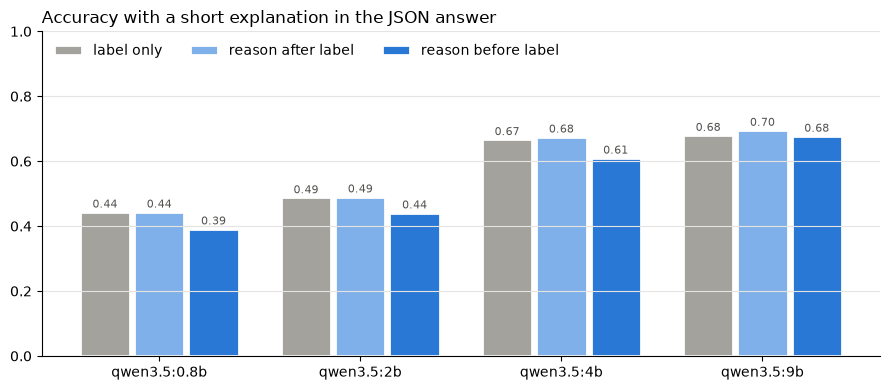

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.27
for j, (variant, color) in enumerate(zip(VARIANTS, ["#a3a29d", "#7fb0ea", "#2a78d6"])):
    values = explain_summary[explain_summary["variant"] == variant].set_index("model").loc[MODELS, "accuracy"]
    bars = ax.bar([i + (j - 1) * width for i in range(len(MODELS))], values, width=width - 0.02, color=color,
                  edgecolor="white", linewidth=2, label=variant)
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:.2f}", (bar.get_x() + bar.get_width() / 2, value), textcoords="offset points",
                    xytext=(0, 3), ha="center", fontsize=8, color="#52514e")
ax.set_xticks(range(len(MODELS)), MODELS)
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="upper left", ncol=3)
style(ax, "Accuracy with a short explanation in the JSON answer")
fig.tight_layout()

In [9]:
# Answers that the reason before the label changes, for the 9b model
model = "qwen3.5:9b"
plain, before = explained["label only", model], explained["reason before label", model]
crosstab = pd.crosstab((plain["correct"]).rename("correct, label only"), before["correct"].rename("correct, reason first"))
print(crosstab, "\n")
fixed = before[~plain["correct"] & before["correct"]].head(3)
for idx, row in fixed.iterrows():
    print(f"query: {row.text}\ngold: {row.label} | label only: {plain.at[idx, 'prediction']}\nreason first: {row.raw}\n")

correct, reason first  False  True 
correct, label only                
False                    107     16
True                      17    245 

query: my card was not in the mail again can you advise?
gold: card_delivery_estimate | label only: card_arrival
reason first: {"reason": "The user is asking about their physical card not arriving via mail, which directly relates to inquiries about card delivery estimates or getting a physical card.", "label": "card_delivery_estimate"}

query: So I just put my top-up into the card and it hasn't changed.
gold: pending_top_up | label only: balance_not_updated_after_cheque_or_cash_deposit
reason first: {"reason": "The user states they have added funds to their card but the balance has not updated, which directly corresponds to the 'pending_top_up' intent.", "label": "pending_top_up"}

query: Paying in card resulted in a fee
gold: card_payment_fee_charged | label only: top_up_by_card_charge
reason first: {"reason": "The user states that paying wi

**Takeaways**

* **No, an explanation does not help here.** Reason after the label: the same accuracy as the label alone
  (within ±0.015; the label is generated before the reason, so only the slightly different prompt can change it).
  Reason before the label: **worse** for the small models (0.8b: 0.44 → 0.39, 2b: 0.49 → 0.44, 4b: 0.67 → 0.61)
  and no gain for 9b (0.68 → 0.68; 16 queries fixed, 17 broken).
* **Why?** The reason is a plausible paraphrase of the query, not an analysis of the 77 intents. The hard cases are
  near-duplicate intents (`card_arrival` vs. `card_delivery_estimate`), and one sentence about the query does not
  separate them. For small models, the extra text even pulls the label towards words in their own sentence. This
  matches DSPy's chain of thought in notebook 03 (2b: 0.40 with vs. 0.53 without).
* **It costs**: about 40–50 instead of 10 generated tokens, so 2–3× the latency (e.g. 9b: 4.6 s → 11–12 s per query).
  The 0.8b and 2b latencies of the "reason before" run may be slightly too high (the GPU was shared during the run).
* **Where it is useful**: a reason after the label is a cheap way to make a decision *readable* for humans
  (auditing, debugging the label set) without changing it. It is not a way to make it *better*; for that, see
  thinking mode in Part 2.

## Part 2: Reasoning (thinking mode)

Qwen3.5 models can produce a reasoning trace before the answer (`think=True`). We compare a small and a
medium model with and without thinking on a balanced subset (5 queries per intent), keeping the
structured output. Thinking runs sample with temperature 0.6, top-p 0.95, top-k 20 (plus Ollama's default
presence penalty of 1.5 for Qwen3.5), because greedy decoding tends to get stuck in loops while reasoning.
This sits between the model card's settings for general (temperature 1.0) and precise tasks
(presence penalty 0). Generation is capped at 4,096 tokens: **a capped trace has no answer**. In Part 3, the
capped traces are continued to 8,192 tokens.

In [10]:
THINK_MODELS = ["qwen3.5:2b", "qwen3.5:4b"]
subset = stratified_subset(dataset.test, per_class=5)  # 385 queries

reasoning, rows = {}, []
for model in THINK_MODELS:
    for think in (False, True):
        reasoning[model, think] = res = run(model, think=think, data=subset)
        rows.append({"model": model, "think": think, **score(res)})
think_summary = pd.DataFrame(rows)
think_summary[["model", "think", "accuracy", "mean_completion_tokens", "mean_latency_s", "truncated_rate"]].round(3)

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

,model,think,accuracy,mean_completion_tokens,mean_latency_s,truncated_rate
0,qwen3.5:2b,False,0.488,12.119,1.242,NaN
1,qwen3.5:2b,True,0.457,2653.730,164.525,0.40
2,qwen3.5:4b,False,0.668,9.844,2.514,NaN
3,qwen3.5:4b,True,0.564,2576.735,310.484,0.33


A plain comparison of the two runs is misleading: every query whose reasoning hits the 4,096-token cap
is counted as wrong, although the model never got to answer. That happens for a third of the queries.
Instead, we use **budget forcing** (explained in Part 3): the reasoning is cut at a *thinking budget* of
2,048 tokens and the model is told to answer right away, so every query gets an answer. For reference, the table
also shows the model thinking as long as it wants (up to 8,192 tokens, using the extended traces of Part 3);
6-8% of those traces never end.

In [11]:
BUDGET_DIR = RESULTS / "thinking_budget"
budgets = pd.read_csv(BUDGET_DIR / "summary_5pc.csv").set_index(["model", "budget"])

def load_jsonl(path):
    df = pd.read_json(path, lines=True)
    return df.assign(idx=df["key"].astype(str).str.split("@").str[0].astype(int))


configs = []
for model in THINK_MODELS:
    name = model.replace(":", "_")
    plain, thought = reasoning[model, False], reasoning[model, True]
    # natural answers within 8k: traces that ended within 4k, plus those that ended during the extension
    late = load_jsonl(BUDGET_DIR / f"{name}_late_answers.jsonl").set_index("idx")["prediction"]
    answer = thought["prediction"].where(thought["done_reason"] == "stop")
    answer.loc[late.index] = late
    configs += [
        {"model": model, "config": "no thinking", "accuracy": score(plain)["accuracy"], "cut_off": 0.0,
         "tokens": plain["completion_tokens"].mean()},
        {"model": model, "config": "thinking, up to 8k", "accuracy": (answer == subset["label"]).mean(),
         "cut_off": answer.isna().mean(), "tokens": budgets.loc[(model, 8192), "mean_thinking_tokens"]},
        {"model": model, "config": "thinking, answer forced at 2k", "accuracy": budgets.loc[(model, 2048), "accuracy"],
         "cut_off": 0.0, "tokens": budgets.loc[(model, 2048), "mean_thinking_tokens"]},
    ]
configs = pd.DataFrame(configs)
configs.round(3)

,model,config,accuracy,cut_off,tokens
0,qwen3.5:2b,no thinking,0.488,0.000,12.119
1,qwen3.5:2b,"thinking, up to 8k",0.564,0.083,3479.135
2,qwen3.5:2b,"thinking, answer forced at 2k",0.590,0.000,1596.821
3,qwen3.5:4b,no thinking,0.668,0.000,9.844
4,qwen3.5:4b,"thinking, up to 8k",0.670,0.062,3294.434
5,qwen3.5:4b,"thinking, answer forced at 2k",0.696,0.000,1649.457


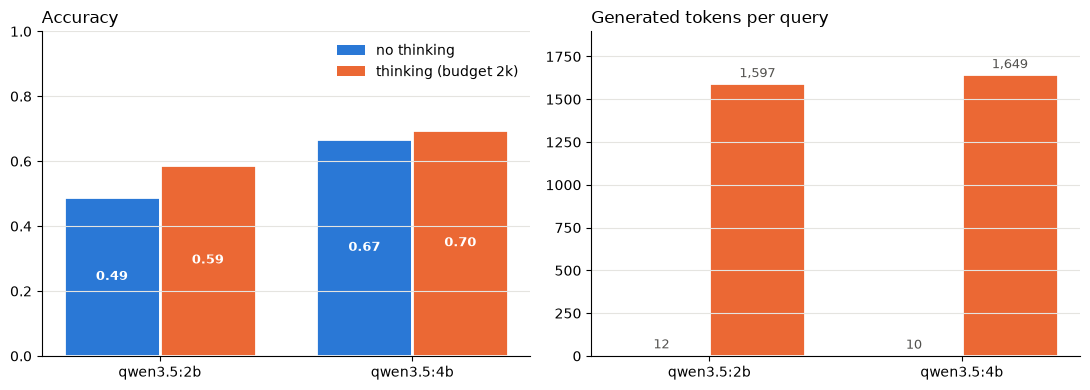

In [12]:
CONFIG_COLORS = {"no thinking": COLORS[0], "thinking, answer forced at 2k": COLORS[1]}
LABELS = {"no thinking": "no thinking", "thinking, answer forced at 2k": "thinking (budget 2k)"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
width = 0.38
for i, model in enumerate(THINK_MODELS):
    for j, (config, color) in enumerate(CONFIG_COLORS.items()):
        row = configs[(configs["model"] == model) & (configs["config"] == config)].iloc[0]
        x = i + (j - 0.5) * width
        axes[0].bar(x, row["accuracy"], width=width, color=color, edgecolor="white", linewidth=2)
        axes[0].annotate(f"{row['accuracy']:.2f}", (x, row["accuracy"] / 2), ha="center", va="center",
                         fontsize=9, color="white", fontweight="bold")
        axes[1].bar(x, row["tokens"], width=width, color=color, edgecolor="white", linewidth=2)
        axes[1].annotate(f"{row['tokens']:,.0f}", (x, row["tokens"]), textcoords="offset points", xytext=(0, 4),
                         ha="center", fontsize=9, color="#52514e")
for ax, title in zip(axes, ["Accuracy", "Generated tokens per query"]):
    ax.set_xticks(range(len(THINK_MODELS)), THINK_MODELS)
    style(ax, title)
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, configs.loc[configs["config"].isin(CONFIG_COLORS), "tokens"].max() * 1.15)
axes[0].legend(handles=[Patch(facecolor=c, label=LABELS[n]) for n, c in CONFIG_COLORS.items()], frameon=False)
fig.tight_layout()

With a sensible budget, thinking **helps**: +10 points for 2b and +3 points for 4b, at about 150x the
tokens (and latency: ~1-2.5 s per query without thinking, minutes with). Letting the model think as long as it
wants (table, up to 8k) is worse than stopping it at 2k: it costs twice the tokens, and a few traces never end.

### Which answers change?

In the original run (cap 4k), almost all answers that thinking "breaks" are queries whose reasoning was cut off.

In [13]:
for model in THINK_MODELS:
    before = reasoning[model, False]["prediction"] == subset["label"]
    thought = reasoning[model, True]
    after = thought["prediction"] == subset["label"]
    cut_off = thought["done_reason"] == "length"
    print(model)
    print(pd.crosstab(before.rename("correct without thinking"), after.rename("correct with thinking")))
    print(f"broken: {(before & ~after).sum()}, of which cut off at 4k: {(before & ~after & cut_off).sum()}\n")

qwen3.5:2b
correct with thinking     False  True 
correct without thinking              
False                       164     33
True                         45    143
broken: 45, of which cut off at 4k: 40

qwen3.5:4b
correct with thinking     False  True 
correct without thinking              
False                       112     16
True                         56    201
broken: 56, of which cut off at 4k: 50



In [14]:
model = THINK_MODELS[0]
plain, thought = reasoning[model, False], reasoning[model, True]
fixed = thought[(plain["prediction"] != subset["label"]) & (thought["prediction"] == subset["label"])]
example = fixed.iloc[0]
print(f"query:    {example.text}\ngold:     {example.label}\nwithout:  {plain.loc[example.name, 'prediction']}\n")
print(f"reasoning ({example.completion_tokens} tokens):\n{example.thinking}")

query:    When will I get my card?
gold:     card_arrival
without:  card_delivery_estimate

reasoning (3422 tokens):
Thinking Process:

1.  **Analyze the Request:**
    *   Task: Intent classification for customer messages sent to a bank.
    *   Input Message: "When will I get my card?"
    *   Output Format: JSON object `{"label": "<intent>"}`.
    *   Allowed Intents: A specific list of 50+ intents provided in the prompt.

2.  **Analyze the Input Message:**
    *   Message: "When will I get my card?"
    *   Key Information: The user is asking about the delivery time or arrival date of their physical bank card.
    *   Match with Allowed Intents:
        *   `card_arrival`: Matches "When will I get my card?" (asking about arrival).
        *   `getting_virtual_card`: Usually asks for activation, not specifically the date of a physical card, though related. However, `card_arrival` is more specific to delivery time.
        *   `get_physical_card`: Asks for a card, but usually implies

## Part 3: How much thinking is worth it? Budget forcing and extension

Two interventions on the reasoning traces from Part 2 (`scripts/run_thinking_budget.py`):

* **Budget forcing**: cut every trace after *b* tokens, append *"Considering the limited time by the user, I have
  to give the solution based on the thinking directly now."* and close the thinking block, so the model must
  answer immediately. Traces that end within the budget keep their natural answer.
* **Extension**: traces that hit the 4,096-token limit are continued by up to 4,096 more tokens (8k total).

Both need the raw prompt, so we send Qwen's chat template ourselves (`raw=True` in Ollama); token positions
are exact thanks to the original Qwen tokenizer. Budget 0 is the run without thinking.

In [15]:
budgets = pd.read_csv(BUDGET_DIR / "summary_5pc.csv")
budgets.pivot(index="budget", columns="model", values=["accuracy", "mean_thinking_tokens", "forced_rate"]).round(3)

accuracy            mean_thinking_tokens            forced_rate  \
model  qwen3.5:2b qwen3.5:4b           qwen3.5:2b qwen3.5:4b  qwen3.5:2b   
budget                                                                     
0           0.488      0.668                0.000      0.000       0.000   
256         0.494      0.639              254.060    256.000       0.971   
512         0.530      0.631              495.312    505.836       0.891   
1024        0.553      0.668              909.195    957.719       0.743   
2048        0.590      0.696             1596.821   1649.457       0.616   
3072        0.569      0.691             2168.917   2161.268       0.512   
4096        0.584      0.691             2644.743   2566.979       0.400   
6144        0.574      0.691             3217.379   3086.075       0.184   
8192        0.574      0.688             3479.135   3294.434       0.083   

                   
model  qwen3.5:4b  
budget             
0           0.000  
256         1.000  
512         0.922  
1024        0.847  
2048        0.548  
3072        0.455  
4096        0.330  
6144        0.177  
8192        0.062

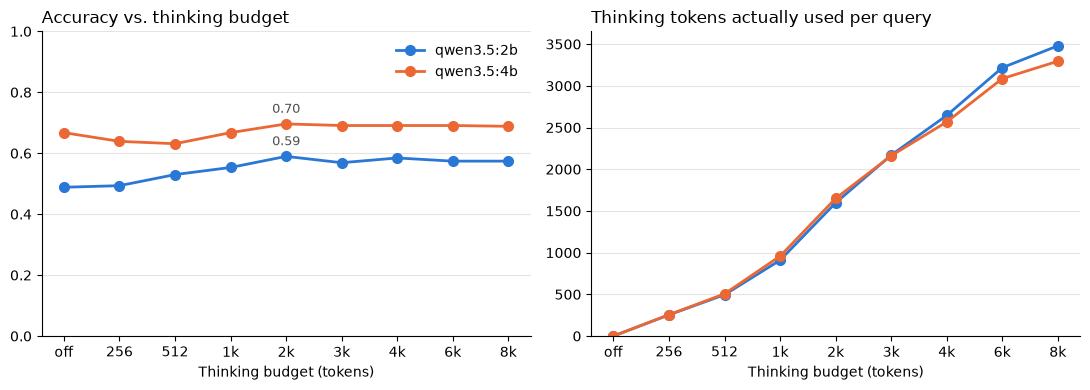

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
levels = sorted(budgets["budget"].unique())
ticks = ["off" if b == 0 else (f"{b // 1024}k" if b >= 1024 else str(b)) for b in levels]
for color, (model, grp) in zip(COLORS, budgets.groupby("model")):
    x = [levels.index(b) for b in grp["budget"]]
    axes[0].plot(x, grp["accuracy"], marker="o", markersize=7, linewidth=2, color=color, label=model)
    axes[1].plot(x, grp["mean_thinking_tokens"], marker="o", markersize=7, linewidth=2, color=color, label=model)
    best = grp.loc[grp["accuracy"].idxmax()]
    axes[0].annotate(f"{best['accuracy']:.2f}", (levels.index(best["budget"]), best["accuracy"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color="#52514e")
for ax, title in zip(axes, ["Accuracy vs. thinking budget", "Thinking tokens actually used per query"]):
    ax.set_xticks(range(len(levels)), ticks)
    ax.set_xlabel("Thinking budget (tokens)")
    style(ax, title)
axes[0].set_ylim(0, 1)
axes[1].set_ylim(bottom=0)
axes[0].legend(frameon=False)
fig.tight_layout()

### Does more room help? The traces that hit the 4,096-token limit

We split the queries by when their reasoning ends: within 4k tokens, between 4k and 8k (only thanks to the
extension), or not even within 8k. For late traces we compare the natural answer with the answer forced at 4k.

In [17]:
rows = []
for model in THINK_MODELS:
    name = model.replace(":", "_")
    label = subset["label"]
    plain, thought = reasoning[model, False]["prediction"], reasoning[model, True]
    ext = load_jsonl(BUDGET_DIR / f"{name}_extension.jsonl").set_index("idx")
    late = load_jsonl(BUDGET_DIR / f"{name}_late_answers.jsonl").set_index("idx")["prediction"]
    forced = load_jsonl(BUDGET_DIR / f"{name}_forced.jsonl")
    forced["budget"] = forced["key"].str.split("@").str[1].astype(int)
    at = lambda b: forced[forced["budget"] == b].set_index("idx")["prediction"]
    early = thought.index[thought["done_reason"] == "stop"]
    never = ext.index[~ext["finished"]]
    acc = lambda pred, idx: (pred.loc[idx] == label.loc[idx]).mean()
    rows += [
        {"model": model, "trace ends": "within 4k", "n": len(early),
         "natural answer": acc(thought["prediction"], early), "no thinking": acc(plain, early)},
        {"model": model, "trace ends": "4k-8k", "n": len(late), "natural answer": acc(late, late.index),
         "forced at 4k": acc(at(4096), late.index), "no thinking": acc(plain, late.index)},
        {"model": model, "trace ends": "never (>8k)", "n": len(never), "forced at 4k": acc(at(4096), never),
         "forced at 8k": acc(at(8192), never), "no thinking": acc(plain, never)},
    ]
pd.DataFrame(rows).round(3)

,model,trace ends,n,natural answer,no thinking,forced at 4k,forced at 8k
0,qwen3.5:2b,within 4k,231,0.762,0.641,NaN,NaN
1,qwen3.5:2b,4k-8k,122,0.336,0.262,0.336,NaN
2,qwen3.5:2b,never (>8k),32,NaN,0.250,0.250,0.125
3,qwen3.5:4b,within 4k,258,0.841,0.802,NaN,NaN
4,qwen3.5:4b,4k-8k,103,0.398,0.388,0.398,NaN
5,qwen3.5:4b,never (>8k),24,NaN,0.417,0.333,0.292


Late answers are no better than answers forced 4k tokens earlier, and traces that never end get *worse*
with more thinking. A small model can notice that it is going in circles, and keep going anyway:

In [18]:
ext = load_jsonl(BUDGET_DIR / "qwen3.5_2b_extension.jsonl")
example = ext[ext["continuation"].str.contains("overthinking", case=False)].iloc[0]
pos = example["continuation"].lower().find("overthinking")
print(f"query: {dataset.test.loc[example['idx'], 'text']}\ngold:  {dataset.test.loc[example['idx'], 'label']}\n")
print("... after 4,096 tokens of reasoning, the continuation reads:\n")
print(example["continuation"][max(0, pos - 900):pos + 300])

query: How do I add the card to my account?
gold:  card_linking

... after 4,096 tokens of reasoning, the continuation reads:

ually physical cards are the default assumption unless specified "virtual". But "add" implies digital.
    *   Okay, I will choose **getting_virtual_card**.

    *   Wait, let me check if there's an intent for "linking". Yes, `card_linking`.
    *   Does "add the card to my account" mean linking? Yes, in some contexts. But usually it means getting a new one.
    *   Okay, I'll go with **get_physical_card**. It's more commonly associated with "how do I get my card".
    *   Wait, I found a similar query in a dataset where the answer was `get_physical_card`.
    *   Let's stick with **get_physical_card**.

    *   Wait, actually, looking at the intent list again, there is `getting_virtual_card`.
    *   Okay, I'll choose **getting_virtual_card**. Why? Because often when people ask "How do I add my card", they mean adding a new one to their existing profile (often